In [27]:
import os
import glob
import cv2
import torch
import random
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET

from tqdm import tqdm
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve
)

from sklearn.manifold import TSNE

import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from ultralytics import YOLO


1. Загрузите набор данных BCCD (Blood Cell Count and Detection). Проведите анализ и визуализацию.

In [28]:
!git clone https://github.com/Shenggan/BCCD_Dataset.git

fatal: destination path 'BCCD_Dataset' already exists and is not an empty directory.


In [29]:
ROOT = "BCCD_Dataset/BCCD"

IMG_DIR = os.path.join(ROOT, "JPEGImages")
ANN_DIR = os.path.join(ROOT, "Annotations")

In [30]:
records = []

xml_files = glob.glob(os.path.join(ANN_DIR, "*.xml"))

for xml_file in xml_files:

    tree = ET.parse(xml_file)
    root = tree.getroot()

    filename = root.find("filename").text

    for obj in root.findall("object"):

        cls = obj.find("name").text

        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        records.append([
            filename,
            cls,
            xmin,
            ymin,
            xmax,
            ymax
        ])

df = pd.DataFrame(records, columns=[
    "filename",
    "class",
    "xmin",
    "ymin",
    "xmax",
    "ymax"
])

print(df.head())

               filename class  xmin  ymin  xmax  ymax
0  BloodImage_00000.jpg   WBC   260   177   491   376
1  BloodImage_00000.jpg   RBC    78   336   184   435
2  BloodImage_00000.jpg   RBC    63   237   169   336
3  BloodImage_00000.jpg   RBC   214   362   320   461
4  BloodImage_00000.jpg   RBC   414   352   506   445


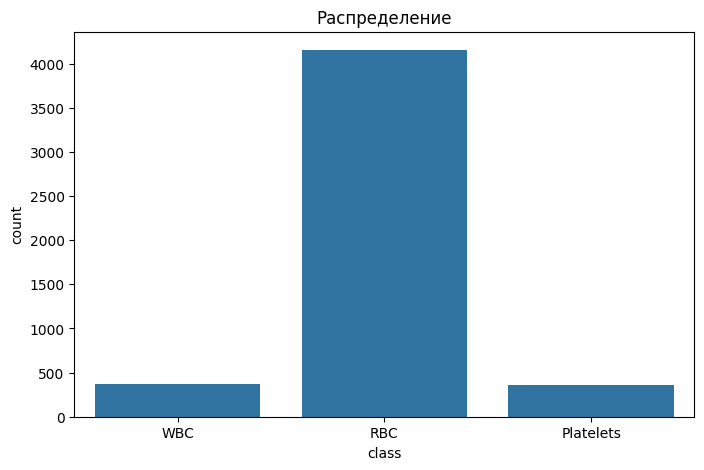

class
RBC          4155
WBC           372
Platelets     361
Name: count, dtype: int64


In [31]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="class")
plt.title("Распределение")
plt.show()
print(df["class"].value_counts())

эритроциты (RBC)

лейкоциты (WBC) 

тромбоциты (Platelets).

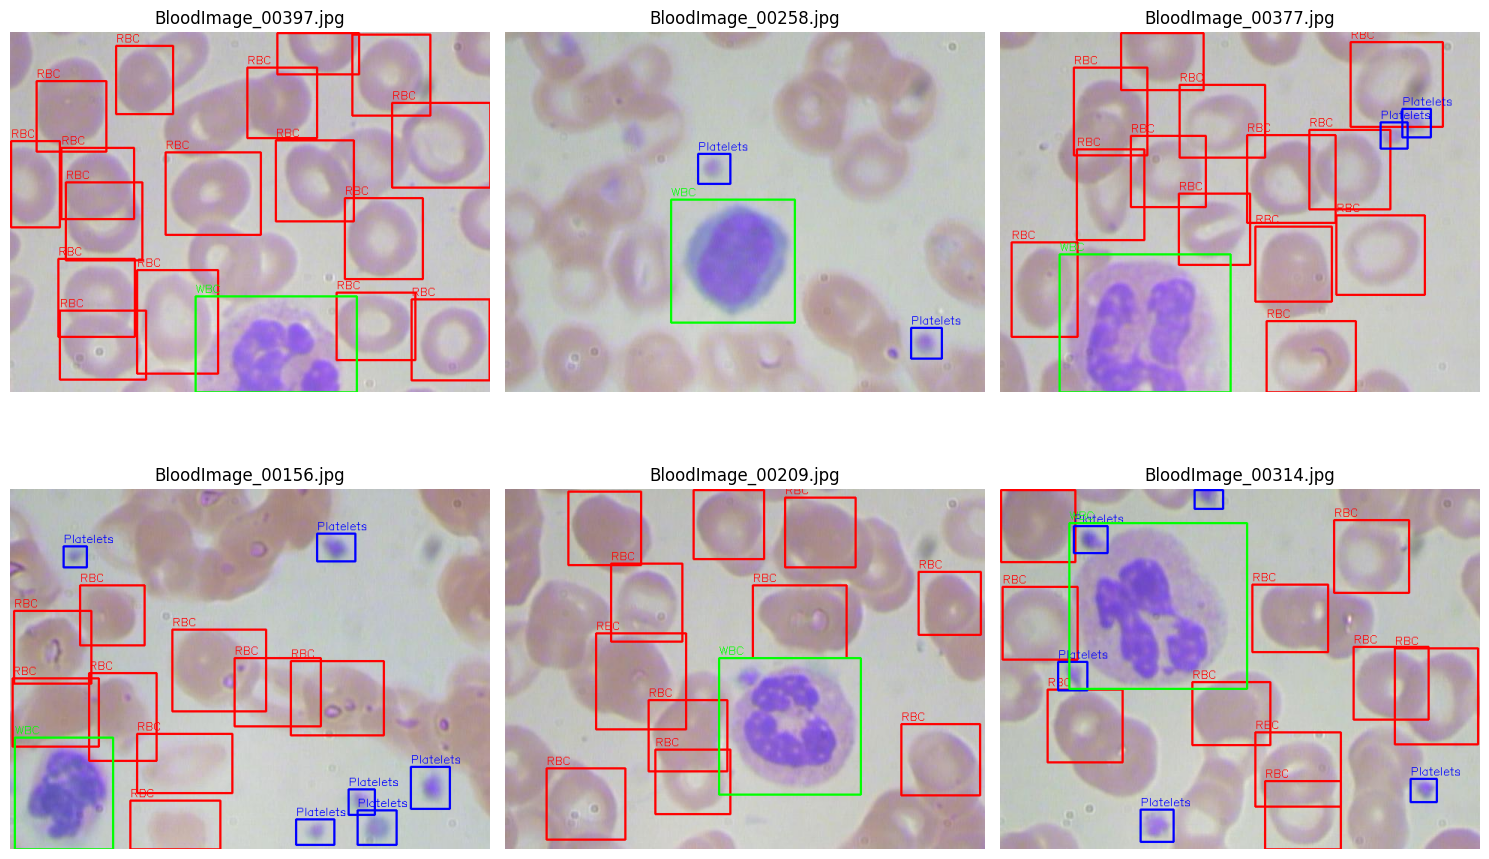

In [32]:
colors = {
    "RBC": (255,0,0),
    "WBC": (0,255,0),
    "Platelets": (0,0,255)
}

sample_images = random.sample(list(df.filename.unique()), 6)

plt.figure(figsize=(15,10))

for i, sample in enumerate(sample_images):

    img = cv2.imread(os.path.join(IMG_DIR, sample))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    sample_boxes = df[df.filename == sample]

    for _, row in sample_boxes.iterrows():

        cv2.rectangle(
            img,
            (row.xmin, row.ymin),
            (row.xmax, row.ymax),
            colors[row["class"]],
            2
        )

        cv2.putText(
            img,
            row["class"],
            (row.xmin, row.ymin - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            colors[row["class"]],
            1
        )

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(sample)

plt.tight_layout()
plt.show()

In [33]:
targets = []

for filename in df.filename.unique():

    subset = df[df.filename == filename]

    rbc = (subset["class"] == "RBC").sum()
    wbc = (subset["class"] == "WBC").sum()
    platelets = (subset["class"] == "Platelets").sum()

    targets.append([
        filename,
        rbc,
        wbc,
        platelets
    ])

targets_df = pd.DataFrame(
    targets,
    columns=["filename", "RBC", "WBC", "Platelets"]
)

print(targets_df.head())


               filename  RBC  WBC  Platelets
0  BloodImage_00000.jpg   19    1          0
1  BloodImage_00001.jpg   18    1          0
2  BloodImage_00002.jpg   15    1          0
3  BloodImage_00003.jpg   15    1          1
4  BloodImage_00004.jpg   11    1          1


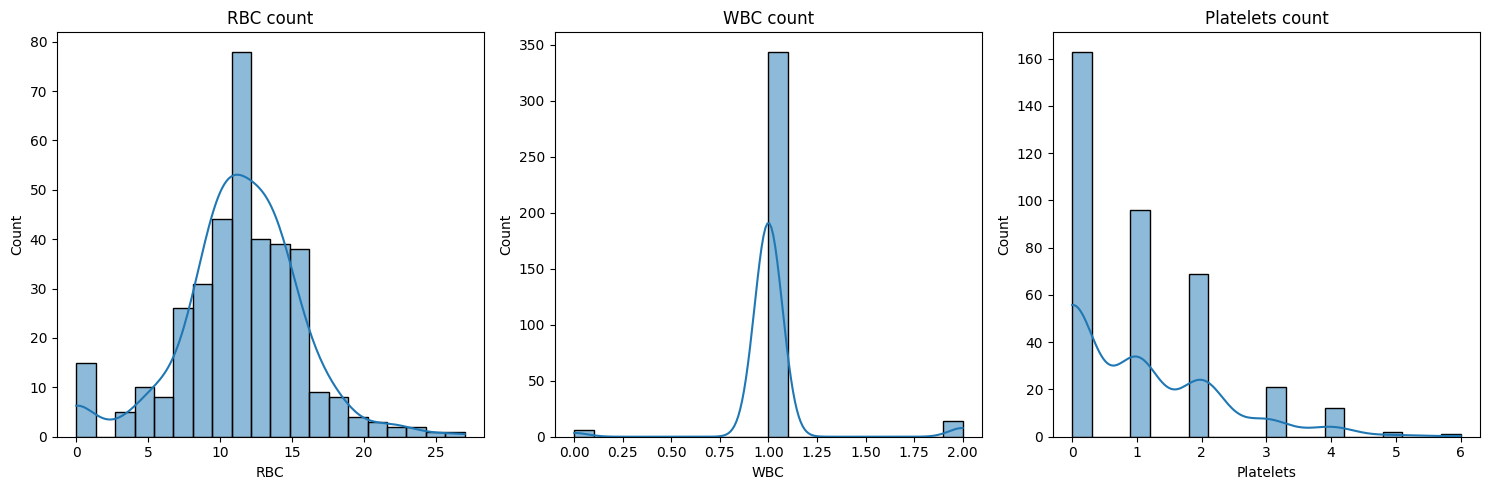

In [34]:
fig, axes = plt.subplots(1,3, figsize=(15,5))

for i, cls in enumerate(["RBC","WBC","Platelets"]):

    sns.histplot(
        targets_df[cls],
        bins=20,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{cls} count")

plt.tight_layout()
plt.show()

In [35]:
train_df, test_df = train_test_split(
    targets_df,
    test_size=0.2,
    random_state=42
)

In [36]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

class BloodDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        img_path = os.path.join(IMG_DIR, row.filename)
        image = Image.open(img_path).convert("RGB")
        image = transform(image)

        target = torch.tensor([
            row.RBC,
            row.WBC,
            row.Platelets
        ], dtype=torch.float32)

        return image, target

In [37]:
train_dataset = BloodDataset(train_df)
test_dataset = BloodDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

2. Решите задачу определения количества клеток каждого класса на изображении двумя способами:

а) прямым предсказанием числа для каждого класса (например, resnet50);

In [38]:
device = "cpu"
model = models.resnet50(weights="DEFAULT")

model.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 3)
)
model = model.to(device)

In [39]:
criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [40]:
class EarlyStopping:
    def __init__(self, patience=3):
        self.patience = patience
        self.counter = 0
        self.best = None
        self.stop_epoch = None

    def __call__(self, loss, epoch):
        if self.best is None or loss < self.best:
            self.best = loss
            self.counter = 0

        else:
            self.counter += 1

        if self.counter >= self.patience:
            self.stop_epoch = epoch
            return True

        return False

In [18]:
early = EarlyStopping(patience=3)
best_loss = float("inf")

history = {
    "epoch": [],
    "train_loss": []
}

EPOCHS = 30

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS}"
    )

    for x, y in loop:
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()

        loop.set_postfix(
            loss=loss.item()
        )

    avg_loss = loss_sum / len(train_loader)

    print(f"\nEpoch {epoch}: avg loss = {avg_loss:.4f}")

    history["epoch"].append(epoch)
    history["train_loss"].append(avg_loss)

    if avg_loss < best_loss:
        best_loss = avg_loss

        torch.save(
            model,
            "best_model.pth"
        )

        print(
            f"Лучшая модель сохранена: loss = {avg_loss:.4f}"
        )

    if early(avg_loss, epoch):
        print(
            f"\nРанняя остановка на эпохе {early.stop_epoch}"
        )
        break

Epoch 1/30: 100%|██████████| 19/19 [00:57<00:00,  3.00s/it, loss=1.96]



Epoch 1: avg loss = 3.4149
Лучшая модель сохранена: loss = 3.4149


Epoch 2/30: 100%|██████████| 19/19 [00:57<00:00,  3.04s/it, loss=1.67]



Epoch 2: avg loss = 1.9969
Лучшая модель сохранена: loss = 1.9969


Epoch 3/30: 100%|██████████| 19/19 [01:00<00:00,  3.16s/it, loss=1.2]  


...


Epoch 16: avg loss = 0.4356


Epoch 17/30: 100%|██████████| 19/19 [01:23<00:00,  4.37s/it, loss=1.17] 



Epoch 17: avg loss = 0.5162


Epoch 18/30: 100%|██████████| 19/19 [01:18<00:00,  4.11s/it, loss=1.33] 


Epoch 18: avg loss = 0.4529

Ранняя остановка на эпохе 18


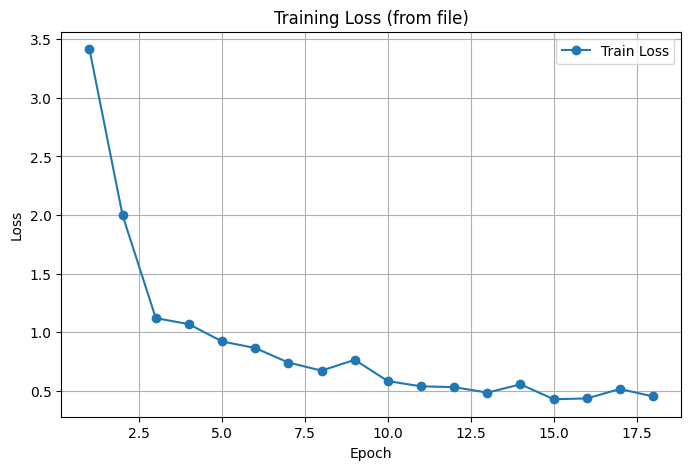

In [ ]:
history_df = pd.read_csv("training_history.csv")
plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.legend()

plt.show()

In [45]:
model = torch.load("best_model.pth", weights_only=False)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [46]:
y_true = []
y_pred = []

with torch.no_grad():
    for x, y in test_loader:
        out = model(x)
        y_true.extend(y.numpy())
        y_pred.extend(out.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [47]:
results = []

for i, cls in enumerate(["RBC", "WBC", "Platelets"]):

    mae = mean_absolute_error(y_true[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))
    r2 = r2_score(y_true[:, i], y_pred[:, i])

    results.append([cls, mae, rmse, r2])

results_df = pd.DataFrame(results, columns=["Class", "MAE", "RMSE", "R2"])

print("Результаты")
print(results_df)

Результаты
       Class       MAE      RMSE        R2
0        RBC  2.850265  3.685553  0.173702
1        WBC  0.179287  0.251063 -0.540830
2  Platelets  0.979780  1.262732  0.083580


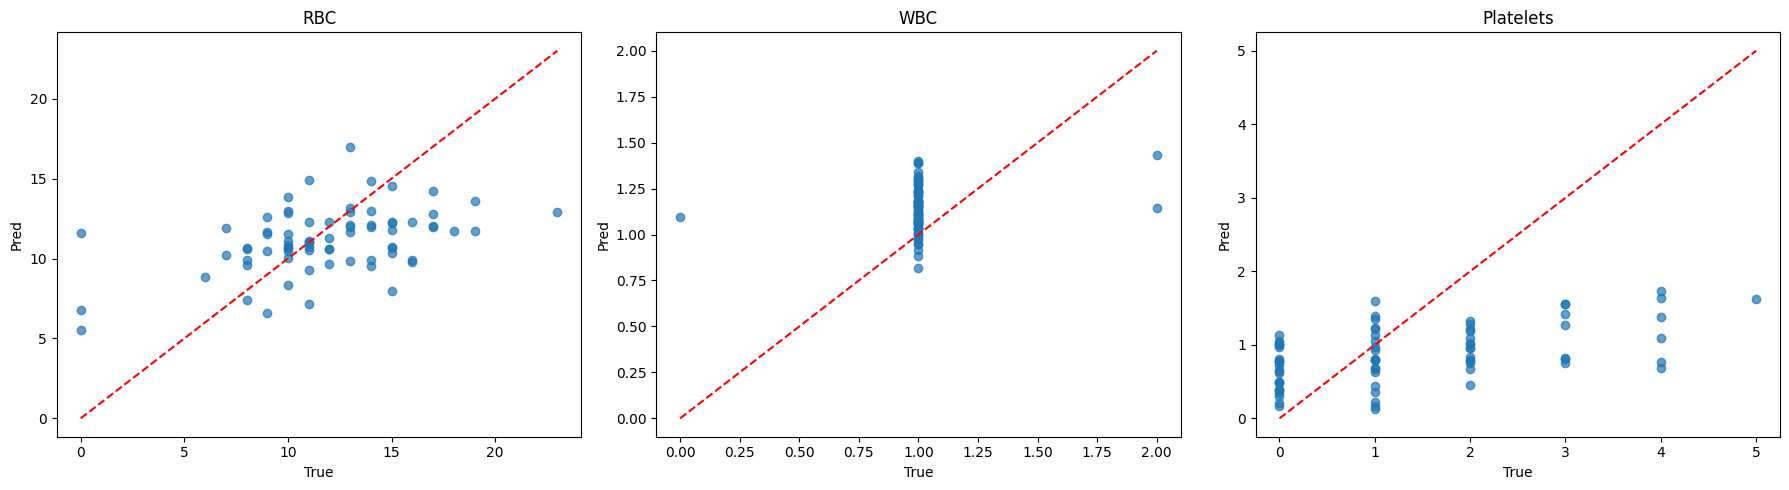

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for i, cls in enumerate(["RBC", "WBC", "Platelets"]):

    axes[i].scatter(y_true[:, i], y_pred[:, i], alpha=0.7)

    axes[i].plot(
        [y_true[:, i].min(), y_true[:, i].max()],
        [y_true[:, i].min(), y_true[:, i].max()],
        "r--"
    )

    axes[i].set_title(cls)
    axes[i].set_xlabel("True")
    axes[i].set_ylabel("Pred")

plt.tight_layout()
plt.show()

На графике WBC (лейкоциты) видно, что модель работает стабильно, так как их на фото мало (от 0 до 2) и точки кучно лежат у линии.

На графике RBC (эритроциты) разброс больше, так как клеток много, они могут слипаться, и модели сложнее выдать точное число.

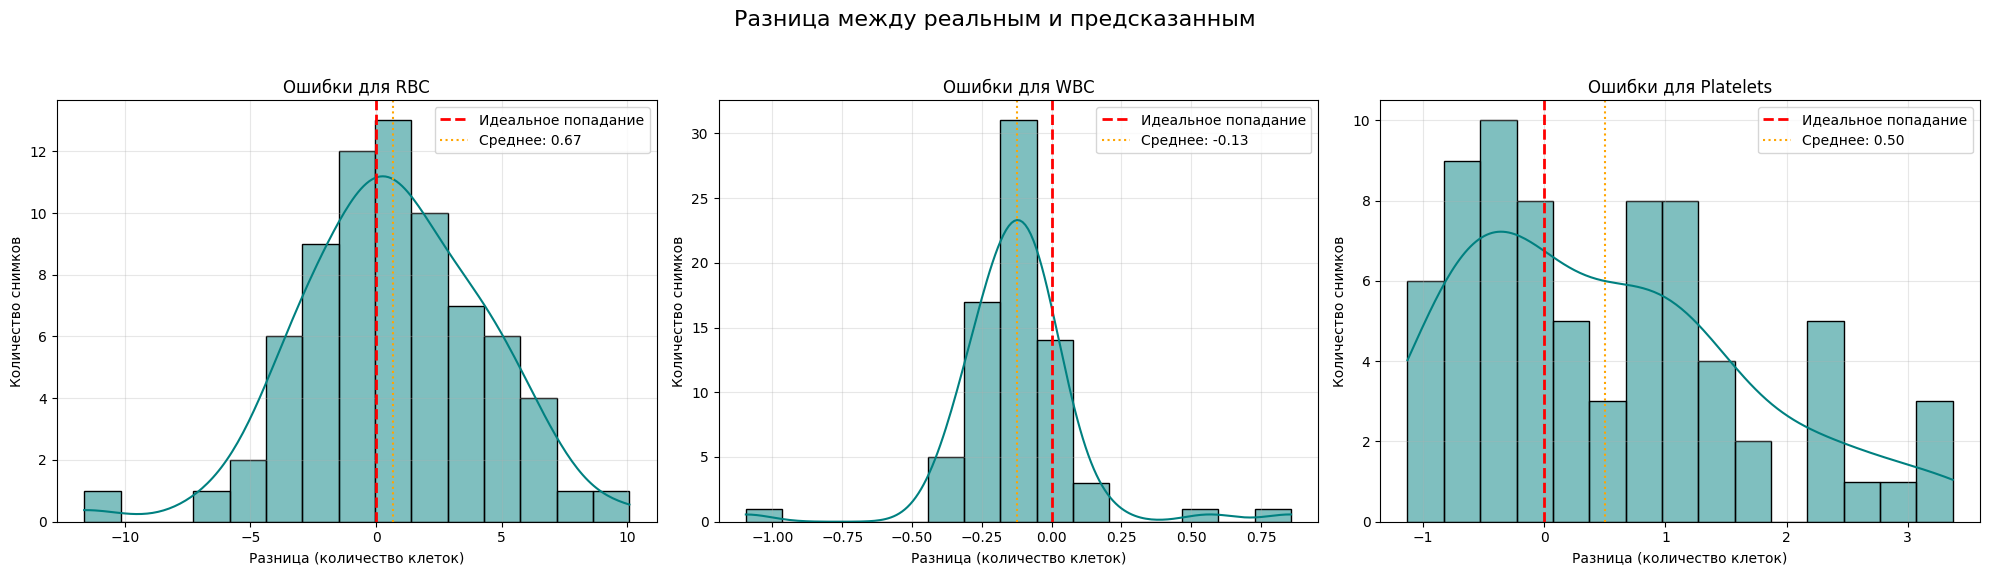

In [49]:
def plot_error_histograms(y_true, y_pred, classes=['RBC', 'WBC', 'Platelets']):
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle('Разница между реальным и предсказанным', fontsize=16)
    
    for i, class_name in enumerate(classes):
        errors = y_true[:, i] - y_pred[:, i]
        sns.histplot(errors, kde=True, ax=axes[i], color='teal', bins=15)

        axes[i].axvline(0, color='red', linestyle='--', linewidth=2, label='Идеальное попадание')

        mean_err = np.mean(errors)
        axes[i].axvline(mean_err, color='orange', linestyle=':', label=f'Среднее: {mean_err:.2f}')
        
        axes[i].set_title(f'Ошибки для {class_name}')
        axes[i].set_xlabel('Разница (количество клеток)')
        axes[i].set_ylabel('Количество снимков')
        axes[i].legend()
        axes[i].grid(alpha=0.3)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_error_histograms(y_true, y_pred)

RBC (Эритроциты): 0.67 модель чаще недосчитывает эритроциты, особенно на плотных кадрах

WBC (Лейкоциты): Среднее отклонение -0.13, почти идеальная работа модели на этом классе

Platelets (Тромбоциты): нестабильность, либо точно, либо ошибается на 1–3 клетки из-за их малого размера и сложности детекции

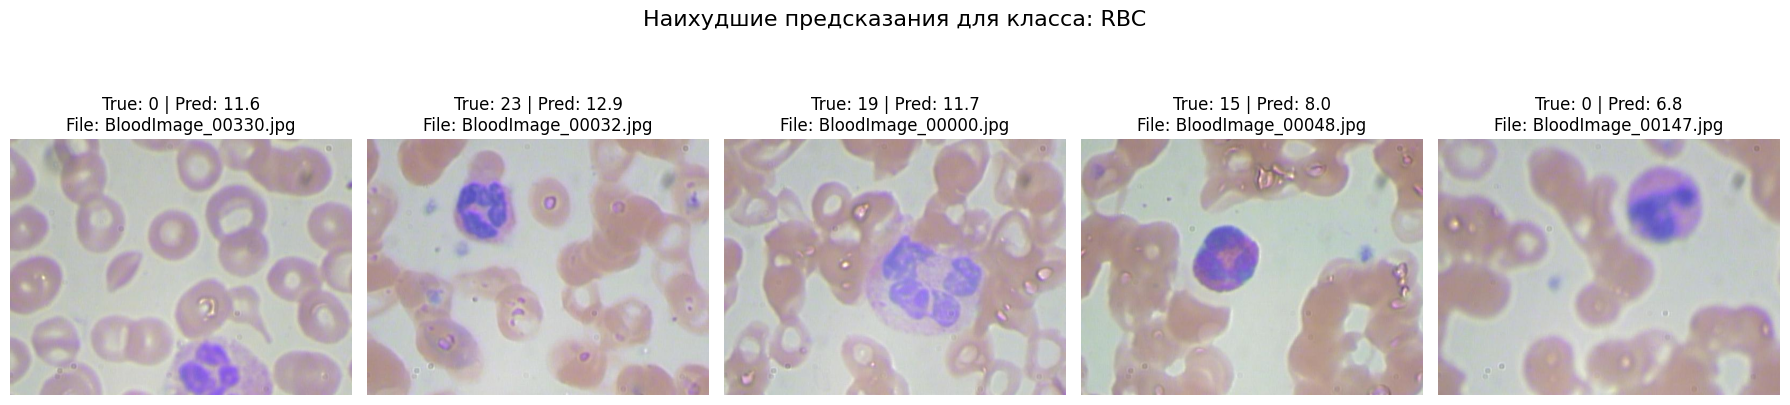

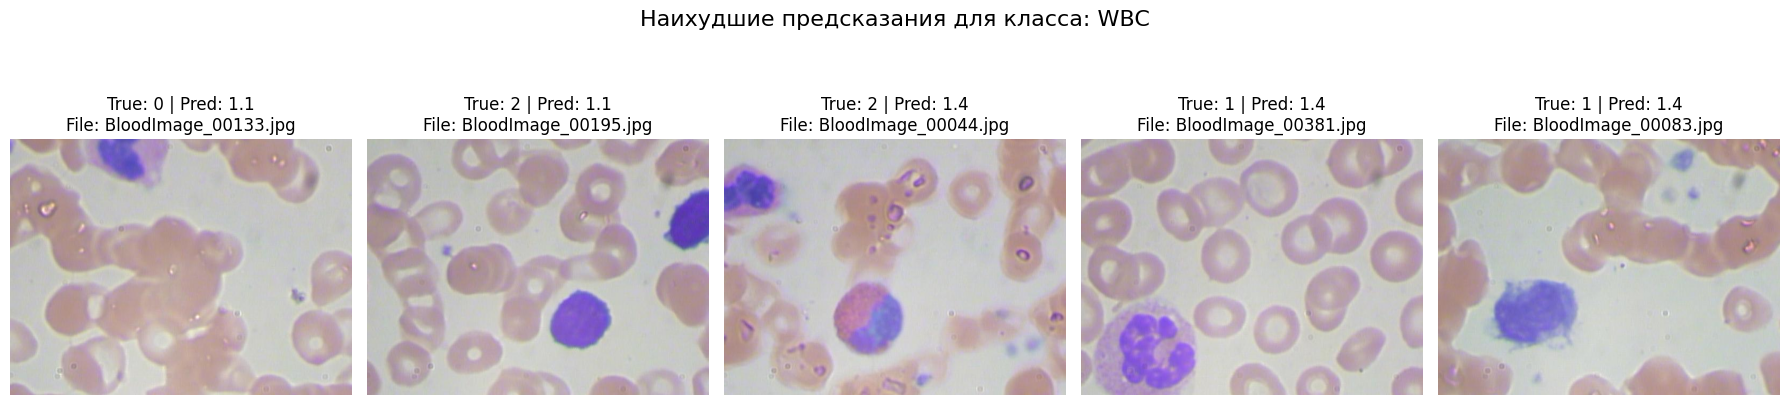

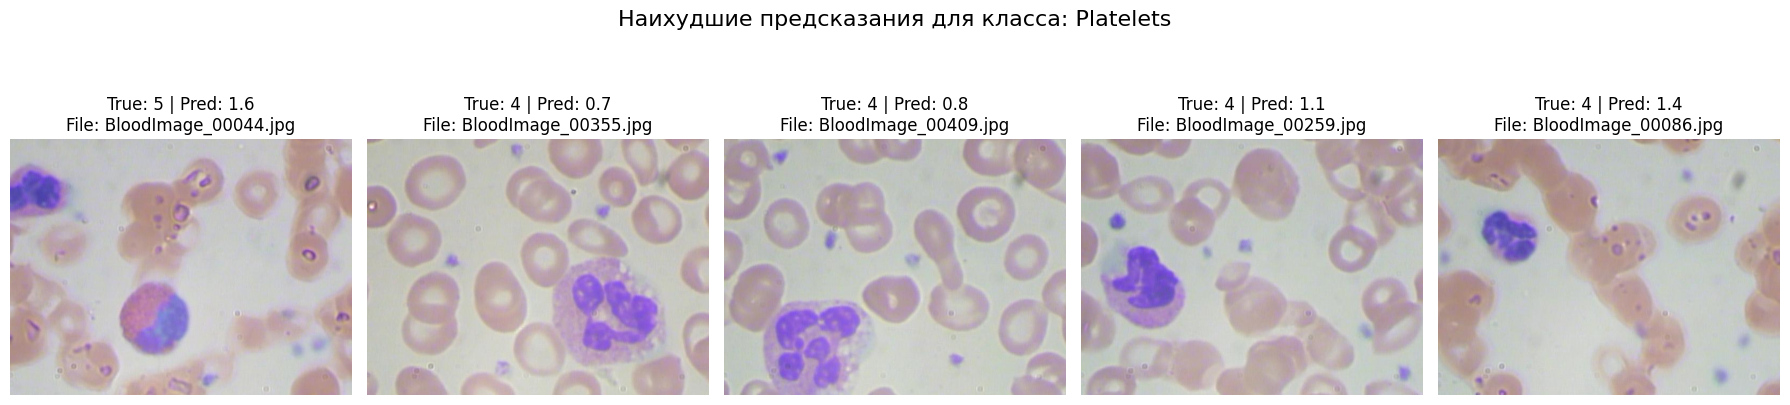

In [50]:
def visualize_worst_errors(y_true, y_pred, test_df, img_dir, classes=['RBC', 'WBC', 'Platelets'], top_n=5):
    abs_errors = np.abs(y_true - y_pred)
    
    for i, class_name in enumerate(classes):
        worst_idx = np.argsort(abs_errors[:, i])[::-1][:top_n]
        
        plt.figure(figsize=(18, 5))
        plt.suptitle(f"Наихудшие предсказания для класса: {class_name}", fontsize=16)
        
        for j, idx in enumerate(worst_idx):
            img_name = test_df.iloc[idx]['filename']
            img_path = os.path.join(img_dir, img_name)
            
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            plt.subplot(1, top_n, j+1)
            plt.imshow(img)
            plt.title(f"\nTrue: {int(y_true[idx, i])} | Pred: {y_pred[idx, i]:.1f}\nFile: {img_name}")
            plt.axis('off')
        
        plt.tight_layout()
        plt.show()

visualize_worst_errors(y_true, y_pred, test_df, IMG_DIR)

Прямая регрессия показала ограниченное качество (низкие/отрицательные R2), особенно на фото с плотными эритроцитами

б) подсчётом по результатам детекции (например, YOLO).

YOLO

In [51]:
YOLO_DIR = "yolo_data"

os.makedirs(f"{YOLO_DIR}/images/train", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/images/val", exist_ok=True)

os.makedirs(f"{YOLO_DIR}/labels/train", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/labels/val", exist_ok=True)

classes = {
    "RBC": 0,
    "WBC": 1,
    "Platelets": 2
}

Вместо координат нужны нормализованные координаты центра x (от 0 до 1)

In [52]:
def convert_box(size, box):
    dw = 1. / size[0]
    dh = 1. / size[1]

    x = (box[0] + box[1]) / 2.0
    y = (box[2] + box[3]) / 2.0

    w = box[1] - box[0]
    h = box[3] - box[2]

    x *= dw
    w *= dw
    y *= dh
    h *= dh

    return x, y, w, h

In [ ]:
all_images = targets_df.filename.values
train_imgs, val_imgs = train_test_split(all_images, test_size=0.2, random_state=42)

for split, images in [("train", train_imgs), ("val", val_imgs)]:

    for img_name in images:

        img_path = os.path.join(IMG_DIR, img_name)
        img = cv2.imread(img_path)
        h, w = img.shape[:2]

        label_path = os.path.join(YOLO_DIR, "labels", split, img_name.replace(".jpg", ".txt"))

        with open(label_path, "w") as f:

            subset = df[df.filename == img_name]

            for _, row in subset.iterrows():

                cls_id = classes[row["class"]]

                box = convert_box(
                    (w, h),
                    (row.xmin, row.xmax, row.ymin, row.ymax)
                )

                f.write(f"{cls_id} {' '.join(map(str, box))}\n")

        save_img_path = os.path.join(YOLO_DIR, "images", split, img_name)

        cv2.imwrite(save_img_path, img)

Прописываем где лежат данные

In [54]:
yaml_text = """
path: yolo_data

train: images/train
val: images/val

names:
  0: RBC
  1: WBC
  2: Platelets
"""

with open("bccd.yaml","w") as f:
    f.write(yaml_text)

In [39]:
detector = YOLO("yolov8n.pt")

detector.train(
    data="bccd.yaml",
    epochs=30,
    imgsz=640
)

Ultralytics 8.4.48  Python-3.10.11 torch-2.11.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bccd.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspe

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000200844C84C0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          

In [55]:
model_yolo = YOLO("runs/detect/train/weights/best.pt")

<img src="runs/detect/train/results.png" width="800"/>

<img src="runs/detect/train/confusion_matrix.png" width="800"/>

<img src="runs/detect/train/confusion_matrix_normalized.png" width="800"/>

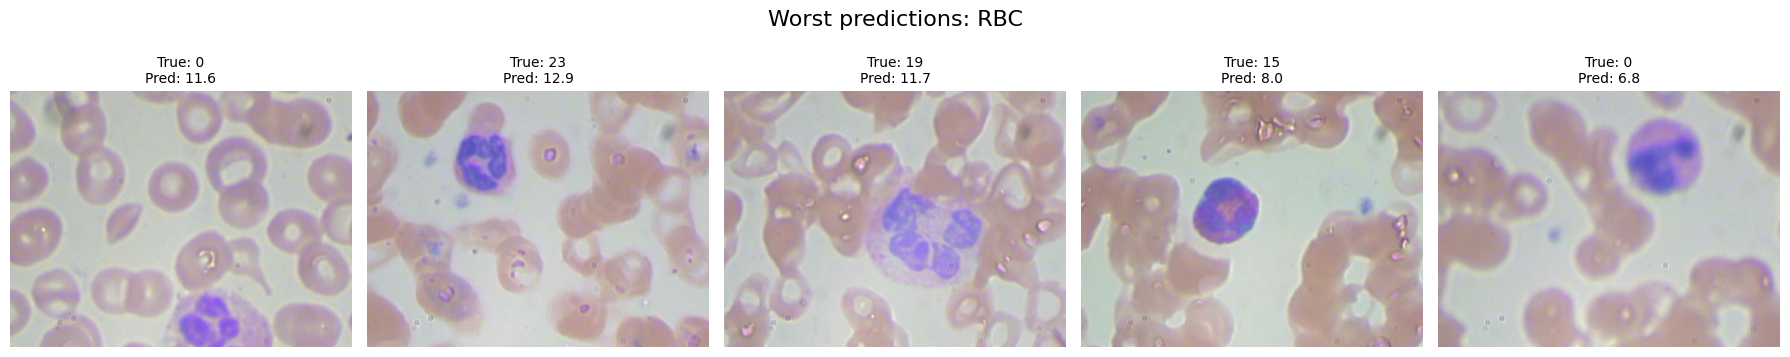

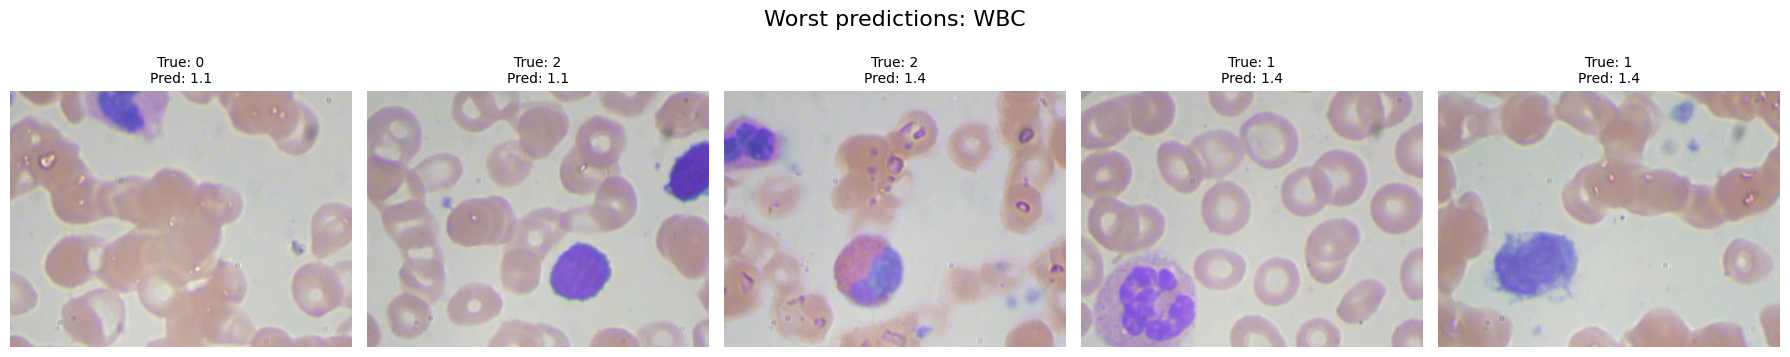

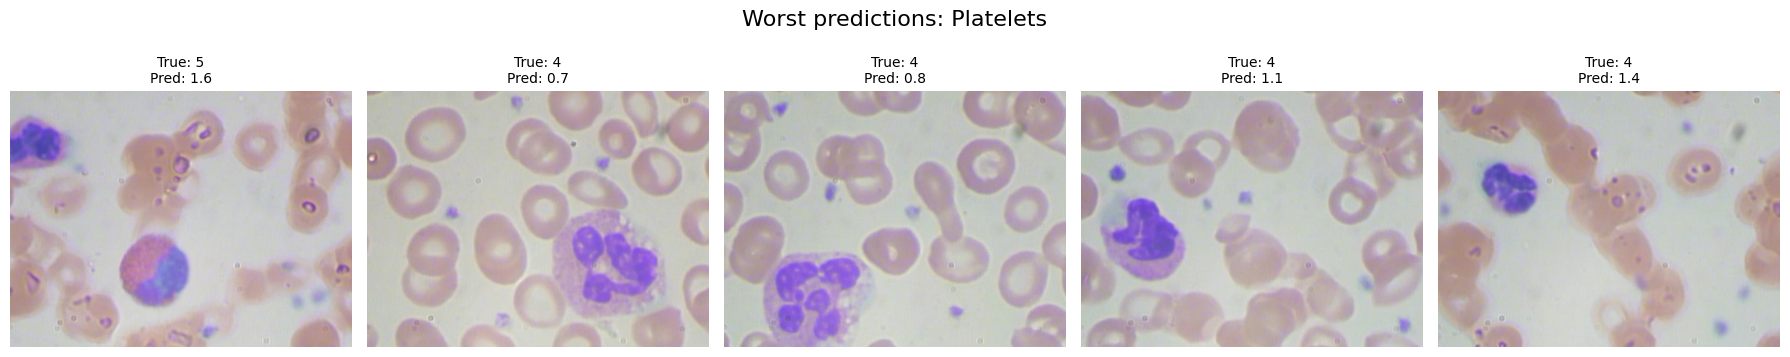

In [ ]:
def show_worst_predictions(y_true, y_pred, test_df, img_dir, classes=["RBC", "WBC", "Platelets"], top_n=5):
    abs_error = np.abs(y_true - y_pred)

    for i, cls in enumerate(classes):
        worst_idx = np.argsort(abs_error[:, i])[::-1][:top_n]

        plt.figure(figsize=(18, 4))
        plt.suptitle(f"Worst predictions: {cls}", fontsize=16)

        for j, idx in enumerate(worst_idx):

            img_name = test_df.iloc[idx]["filename"]
            img = cv2.imread(os.path.join(img_dir, img_name))

            if img is None:
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.subplot(1, top_n, j + 1)
            plt.imshow(img)

            plt.title(f"True: {int(y_true[idx, i])}\nPred: {y_pred[idx, i]:.1f}", fontsize=10)
            plt.axis("off")

        plt.tight_layout()
        plt.show()

show_worst_predictions(y_true, y_pred, test_df, IMG_DIR)

In [65]:
metrics = model_yolo.val(plots=True)

print("\nYOLO")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.48  Python-3.10.11 torch-2.11.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
val: Fast image access  (ping: 0.10.0 ms, read: 6.00.8 MB/s, size: 37.5 KB)
val: Scanning C:\Users\Дина\Desktop\yolo_data\labels\val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.4s/it 7.2s2.1ss
                   all         73       1038      0.887      0.892      0.931      0.643
                   RBC         70        864      0.788      0.836      0.886      0.619
                   WBC         72         74      0.979          1      0.994      0.822
             Platelets         49        100      0.894      0.841      0.912      0.487
Speed: 1.4ms preprocess, 73.1ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to C:\Users\\Desktop\runs\detect\val-2

YOLO
mAP50: 0.9310487110791493
mAP50-95: 0.6429146704559696


3. Организуйте OOD-детекцию (Out-of-Distribution) для размытых и зашумлённых изображений.

Отличать «нормальные» снимки крови от «аномальных»

In [66]:
def add_blur(img):
    return cv2.GaussianBlur(img, (15,15), 0)

def add_noise(img):
    noise = np.random.normal(0, 25, img.shape).astype(np.uint8)
    return cv2.add(img, noise)

In [67]:
feature_extractor = nn.Sequential(*list(model.children())[:-1])
feature_extractor.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [127]:
train_features = []

with torch.no_grad():
    for images, _ in train_loader:
        images = images.to(device)
        feats = feature_extractor(images)
        feats = feats.flatten(1)
        train_features.append(feats.cpu().numpy())

train_features = np.concatenate(train_features, axis=0)

In [ ]:
mean_vec = np.mean(train_features, axis=0)
std_vec = np.std(train_features, axis=0) + 1e-6
train_features_norm = (train_features - mean_vec) / std_vec
cov = np.cov(train_features_norm, rowvar=False)
cov += np.eye(cov.shape[0]) * 1e-3
inv_cov = np.linalg.pinv(cov)

# расстояние Махаланобиса - учитывает связи между признаками и их разброс
def mahalanobis_score(feat):
    diff = feat - 0
    return np.sqrt(diff @ inv_cov @ diff.T)

In [130]:
def extract_feature(img):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(img)
    x = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        feat = feature_extractor(x)

    feat = feat.flatten().cpu().numpy()
    feat = (feat - mean_vec) / std_vec

    return feat

In [131]:
def ood_score(img):
    feat = extract_feature(img)
    score = mahalanobis_score(feat)
    return np.log1p(score)

In [141]:
sample = cv2.imread(os.path.join(IMG_DIR, random.choice(all_images)))

blurred = add_blur(sample)
noisy = add_noise(sample)

print("\nOOD scores:")
print("Original:", ood_score(sample))
print("Blurred:", ood_score(blurred))
print("Noisy:", ood_score(noisy))


OOD scores:
Original: 2.890207172462616
Blurred: 6.807021200988005
Noisy: 7.023153020357677


Original → изображение похоже на ID

Blurred → теряет текстуру клеток

Noisy → ещё сильнее ломает структуру

In [142]:
id_scores = []
ood_scores = []

for img_name in test_df.filename.values[:20]:

    img = cv2.imread(os.path.join(IMG_DIR, img_name))
    id_scores.append(ood_score(img))
    blurred = add_blur(img)
    ood_scores.append(ood_score(blurred))

labels = [0]*len(id_scores) + [1]*len(ood_scores)
scores = id_scores + ood_scores
auc = roc_auc_score(labels, scores)
print("OOD AUROC:", auc)

OOD AUROC: 0.96


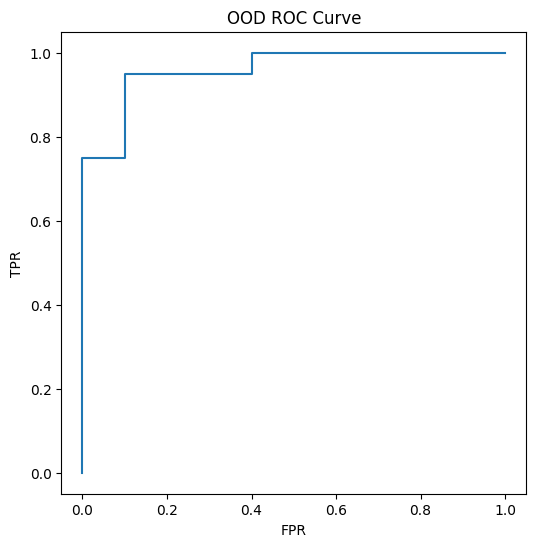

In [143]:
fpr, tpr, _ = roc_curve(labels, scores)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("OOD ROC Curve")
plt.show()

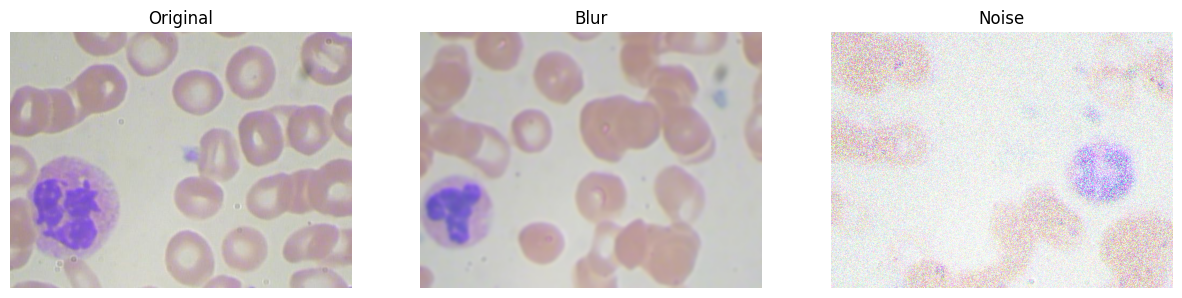

In [144]:
img_name = random.choice(all_images)
img_path = os.path.join(IMG_DIR, img_name)

sample_img = cv2.imread(img_path)
fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original")

ax[1].imshow(cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB))
ax[1].set_title("Blur")

ax[2].imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
ax[2].set_title("Noise")

for a in ax:
    a.axis("off")

plt.show()

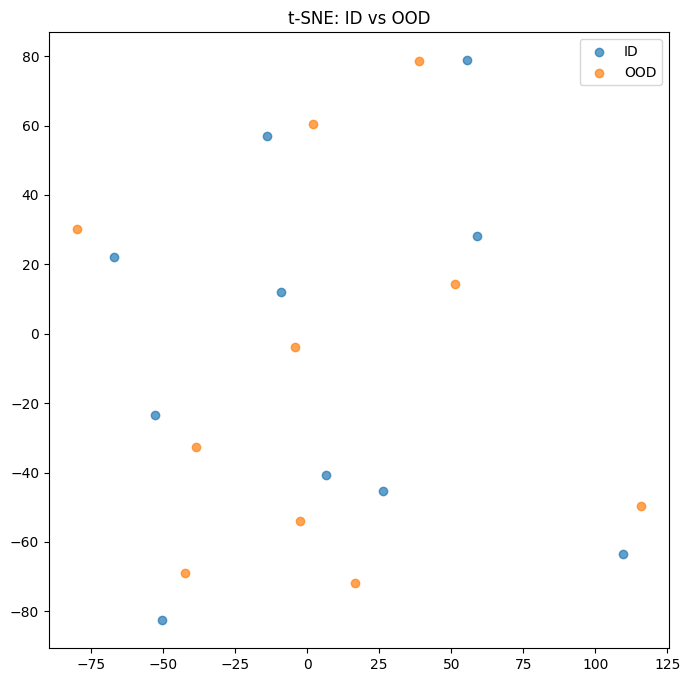

In [145]:
features = []
labels_tsne = []

for img_name in test_df.filename.values[:10]:

    img = cv2.imread(os.path.join(IMG_DIR, img_name))

    if img is None:
        continue

    for version, lbl in [
        (img, "ID"),
        (add_blur(img), "OOD")
    ]:

        im = cv2.cvtColor(version, cv2.COLOR_BGR2RGB)
        im = Image.fromarray(im)

        x = transform(im).unsqueeze(0)

        with torch.no_grad():
            feat = feature_extractor(x)

        features.append(feat.squeeze().cpu().numpy())
        labels_tsne.append(lbl)

features = np.array(features)
tsne = TSNE(n_components=2, random_state=42, perplexity=5)
emb = tsne.fit_transform(features)
plt.figure(figsize=(8, 8))

for lbl in ["ID", "OOD"]:

    idx = np.array(labels_tsne) == lbl

    plt.scatter(
        emb[idx, 0],
        emb[idx, 1],
        label=lbl,
        alpha=0.7
    )

plt.legend()
plt.title("t-SNE: ID vs OOD")
plt.show()

In [146]:
print("Итоги:")
print("\nResNet50:")
print(results_df)

print("\nYOLO:")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("\nOOD:")
print("AUROC:", auc)

Итоги:

ResNet50:
       Class       MAE      RMSE        R2
0        RBC  2.850265  3.685553  0.173702
1        WBC  0.179287  0.251063 -0.540830
2  Platelets  0.979780  1.262732  0.083580

YOLO:
mAP50: 0.9310487110791493
mAP50-95: 0.6429146704559696

OOD:
AUROC: 0.96


** Расширьте возможности OOD-детекции так, чтобы она была лучше приближена к реальным данным, например, используйте изображения бактерий, других тканей (не крови) и т.п.


In [175]:
BCCD_PATH = "BCCD_Dataset/BCCD/JPEGImages"
DIBAS_PATH = "DIBaS"

In [157]:
import warnings
warnings.filterwarnings("ignore")

def load_images(folder, limit=800):

    exts = ["*.jpg", "*.jpeg", "*.png", "*.tif", "*.tiff"]

    paths = []

    for ext in exts:
        paths += glob.glob(os.path.join(folder, "**", ext), recursive=True)

    print(folder, "found:", len(paths))

    images = []

    for p in paths[:limit]:

        try:
            img = Image.open(p).convert("RGB")
            img = np.array(img)

            images.append(img)

        except:
            continue

    return images

In [176]:
bccd_images = load_images(BCCD_PATH, 800)
dibas_images = load_images(DIBAS_PATH, 800)

BCCD_Dataset/BCCD/JPEGImages found: 364
DIBaS found: 692


In [211]:
def add_blur(img):
    k = random.choice([3,5,7])
    return cv2.GaussianBlur(img, (k,k), 0)

def add_noise(img):
    noise = np.random.normal(0, 25, img.shape).astype(np.uint8)
    return cv2.add(img, noise)

def augment_ood(img):
    return random.choice([add_blur, add_noise])(img)

In [212]:
def extract_feature(img):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(img)
    x = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        feat = feature_extractor(x)

    return feat.flatten().cpu().numpy()

In [213]:
def ood_score(img):
    feat = extract_feature(img)
    feat = feat / (np.linalg.norm(feat) + 1e-8)
    ref = mean_vec / (np.linalg.norm(mean_vec) + 1e-8)
    return 1 - np.dot(feat, ref)

In [215]:
id_scores = []
ood_scores = []

n = min(20, len(bccd_images))

for img in bccd_images[:n]:
    id_scores.append(ood_score(img))
    aug_img = augment_ood(img)
    ood_scores.append(ood_score(aug_img))

In [218]:
labels = [0]*len(id_scores) + [1]*len(ood_scores)
scores = id_scores + ood_scores

auc = roc_auc_score(labels, scores)

print("OOD AUROC:", auc)

OOD AUROC: 0.76


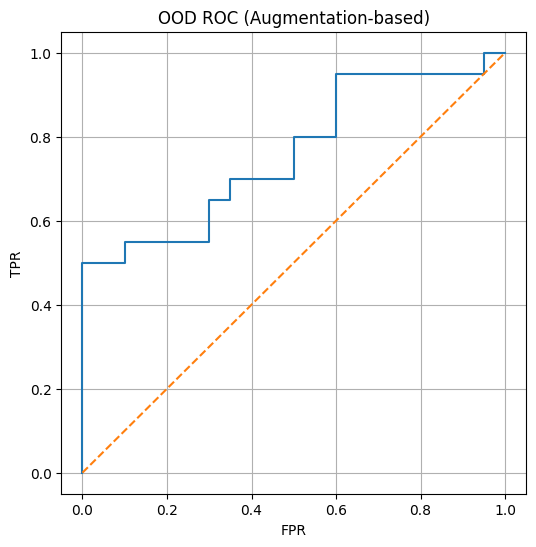

In [ ]:
fpr, tpr, _ = roc_curve(labels, scores)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],"--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("OOD ROC")
plt.grid()
plt.show()

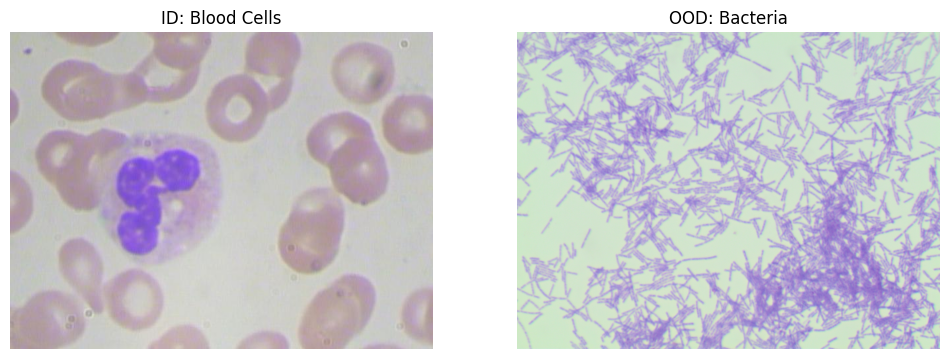

In [221]:
sample_img = random.choice(bccd_images)
ood_img = random.choice(dibas_images)
fig, ax = plt.subplots(1, 2, figsize=(12,5))

ax[0].imshow(sample_img)
ax[0].set_title("ID: Blood Cells")

ax[1].imshow(ood_img)
ax[1].set_title("OOD: Bacteria")

for a in ax:
    a.axis("off")

plt.show()

In [222]:
features = []
labels_tsne = []

for img in bccd_images[:10]:
    feat = extract_feature(img)
    features.append(feat)
    labels_tsne.append("ID")

for img in dibas_images[:10]:
    feat = extract_feature(img)
    features.append(feat)
    labels_tsne.append("OOD")

In [223]:
features = np.array(features)

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=5
)

emb = tsne.fit_transform(features)

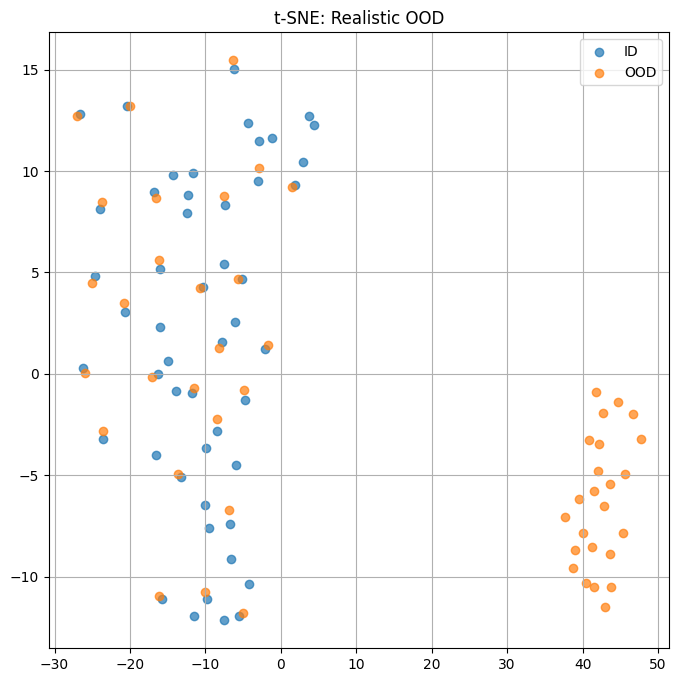

In [226]:
features = []
labels_tsne = []

for img in bccd_images[:50]:
    features.append(extract_feature(img))
    labels_tsne.append("ID")

for img in bccd_images[:50]:
    features.append(extract_feature(augment_ood(img)))
    labels_tsne.append("OOD")

features = np.array(features)

emb = TSNE(n_components=2, perplexity=10, random_state=42).fit_transform(features)

plt.figure(figsize=(8,8))

for lbl in ["ID","OOD"]:
    idx = np.array(labels_tsne) == lbl
    plt.scatter(emb[idx,0], emb[idx,1], label=lbl, alpha=0.7)

plt.legend()
plt.title("t-SNE: Realistic OOD")
plt.grid()
plt.show()